# 🚀 Practice Day 48

**📅 Date:** **2026-10-31**  
**📁 Category:** **Phase 2 · SQL 기초(DuckDB) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice fundamental SQL commands (SELECT, WHERE, GROUP BY, ORDER BY, COUNT/SUM/AVG) using DuckDB on a single table
  (DuckDB로 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 등 기본 SQL 명령어를 단일 테이블에 연습)
- Find which services are ordered most, how orders break down by status, and which service costs the most on average
  (어떤 서비스가 가장 많이 주문되는지, 주문 상태별 비율은 어떤지, 어떤 서비스의 평균 비용이 가장 높은지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Fresh Press Cleaners — Order Records / Fresh Press 세탁소 — 주문 기록

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** A single table of 380 order records from January-May 2024. Covers 4 service types (Wash & Fold, Dry Cleaning, Alterations, Shoe Cleaning) and 3 statuses (Completed, Ready for Pickup, In Progress). Costs are in USD. Clean — no missing values or duplicates — so the focus stays on core DuckDB SELECT/WHERE/GROUP BY/ORDER BY and aggregate functions.
(2024년 1~5월 동안의 주문 기록 380건을 담은 단일 테이블입니다. 4개 서비스(Wash & Fold/Dry Cleaning/Alterations/Shoe Cleaning), 3가지 상태(Completed/Ready for Pickup/In Progress)를 포함합니다. 비용은 USD입니다. 결측치·중복 없이 깨끗한 데이터로, DuckDB의 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 연습에 초점을 둡니다.)

## Dataset Preview

In [35]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate laundry / dry-cleaning shop order records ---
n = 380
service_types = ['Wash & Fold', 'Dry Cleaning', 'Alterations', 'Shoe Cleaning']
service_w = [0.42, 0.30, 0.16, 0.12]
avg_cost = {'Wash & Fold': 18, 'Dry Cleaning': 32, 'Alterations': 25, 'Shoe Cleaning': 15}  # USD

statuses = ['Completed', 'Ready for Pickup', 'In Progress']
status_w = [0.72, 0.16, 0.12]

service_choice = rng.choice(service_types, size=n, p=service_w)
status_choice = rng.choice(statuses, size=n, p=status_w)
order_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 150, size=n), unit='D')

cost = np.array([avg_cost[s] for s in service_choice]) * rng.normal(1.0, 0.10, n)
cost = cost.round(1)  # nearest $0.10

df = pd.DataFrame({
    'order_id': [f'O{str(i+1).zfill(4)}' for i in range(n)],
    'service_type': service_choice,
    'cost': cost,
    'order_date': order_dates,
    'status': status_choice
})
df = df.sort_values('order_date').reset_index(drop=True)

df.head(10)


,order_id,service_type,cost,order_date,status
0,O0102,Dry Cleaning,30.9,2024-01-01,Completed
1,O0219,Shoe Cleaning,16.9,2024-01-01,In Progress
2,O0030,Dry Cleaning,33.1,2024-01-01,In Progress
3,O0287,Wash & Fold,17.8,2024-01-02,Ready for Pickup
4,O0162,Shoe Cleaning,14.1,2024-01-02,Completed
5,O0012,Shoe Cleaning,14.7,2024-01-02,Completed
6,O0243,Wash & Fold,15.4,2024-01-02,In Progress
7,O0104,Shoe Cleaning,15.5,2024-01-03,Completed
8,O0132,Shoe Cleaning,13.6,2024-01-03,Ready for Pickup
9,O0074,Wash & Fold,19.6,2024-01-03,Completed


## Dataset Information

In [36]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      380 non-null    str           
 1   service_type  380 non-null    str           
 2   cost          380 non-null    float64       
 3   order_date    380 non-null    datetime64[us]
 4   status        380 non-null    str           
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 15.0 KB

Shape: (380, 5)


,order_id,service_type,cost,order_date,status
count,380,380,380.000000,380,380
unique,380,4,NaN,NaN,3
top,O0102,Wash & Fold,NaN,NaN,Completed
freq,1,161,NaN,NaN,272
mean,NaN,NaN,23.159474,2024-03-13 13:15:47.368421,NaN
min,NaN,NaN,11.400000,2024-01-01 00:00:00,NaN
25%,NaN,NaN,17.400000,2024-02-02 18:00:00,NaN
50%,NaN,NaN,20.350000,2024-03-12 00:00:00,NaN
75%,NaN,NaN,29.900000,2024-04-20 06:00:00,NaN
max,NaN,NaN,39.900000,2024-05-29 00:00:00,NaN


---
# ❓ Business Questions

1. **(Analysis)** Which service type has been ordered the most, and which the least?
   (어떤 서비스가 가장 많이/적게 주문되었는가?)
2. **(Analysis)** What percentage of orders are Completed, Ready for Pickup, or In Progress?
   (전체 주문 중 완료·픽업대기·진행중 비율은 각각 몇 %인가?)
3. **(Analysis)** Which service type has the highest average cost, and which the lowest?
   (평균 비용이 가장 높은/낮은 서비스는?)
4. **(Visualization)** Compare order counts across all 4 service types.
   (4개 서비스의 주문건수를 비교하면?)
5. **(Visualization)** Show the breakdown of order status (Completed/Ready for Pickup/In Progress).
   (주문 상태(완료/픽업대기/진행중) 비중을 보면?)

---
# 🔍 Data Cleaning Check


In [37]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
order_id        0
service_type    0
cost            0
order_date      0
status          0
dtype: int64

Duplicate rows: 0

Dtypes
order_id                   str
service_type               str
cost                   float64
order_date      datetime64[us]
status                     str
dtype: object

Column names
['order_id', 'service_type', 'cost', 'order_date', 'status']

Text columns — unique counts
order_id        380
service_type      4
status            3
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which service type has been ordered the most, and which the least? (어떤 서비스가 가장 많이/적게 주문되었는가?)

**Result:** Wash & Fold has the most orders at **161**. Shoe Cleaning has the fewest at **39**. The gap is **122**.  
(주문 1위는 Wash & Fold 161건, 맨 아래는 Shoe Cleaning 39건. 차이는 122건)

**Insight:** Dry Cleaning is next at **114**, which is **47** below Wash & Fold. Alterations has **66**. The four counts add to **380**.  
(다음은 Dry Cleaning 114건으로 Wash & Fold보다 47건 적음. Alterations는 66건. 네 건수를 더하면 380건)

In [38]:
# Question 1 (DuckDB): order count by service_type
import duckdb

order_count_by_service_type = duckdb.sql("""
    SELECT 
        service_type,
        COUNT(*) AS order_count
    FROM df
    GROUP BY service_type
    ORDER BY order_count DESC
""").df()

order_count_by_service_type

,service_type,order_count
0,Wash & Fold,161
1,Dry Cleaning,114
2,Alterations,66
3,Shoe Cleaning,39


## Question 2

**Question:** What percentage of orders are Completed, Ready for Pickup, or In Progress? (완료·픽업대기·진행중 비율은?)

**Result:** Completed is **71.58%**. Ready for Pickup is **16.58%**. In Progress is **11.84%**.  
(Completed 71.58%, Ready for Pickup 16.58%, In Progress 11.84%)

**Insight:** Ready for Pickup and In Progress together are **28.42%**. Completed is **59.74** percentage points above In Progress.  
(Ready for Pickup과 In Progress를 더하면 28.42%. Completed는 In Progress보다 59.74%p 높음)

In [39]:
# Question 2 (DuckDB): status breakdown as a % of all orders
breakdown_by_status = duckdb.sql("""
    SELECT 
        status,
        ROUND(COUNT(*) / (SELECT COUNT(*) FROM df) * 100, 2) AS status_percentage
    FROM df
    GROUP BY status
    ORDER BY status_percentage DESC
""").df()

breakdown_by_status

,status,status_percentage
0,Completed,71.58
1,Ready for Pickup,16.58
2,In Progress,11.84


## Question 3

**Question:** Which service type has the highest average cost, and which the lowest? (평균 비용 최고·최저 서비스는?)

**Result:** Dry Cleaning has the highest average cost at **$32.34**. Shoe Cleaning has the lowest at **$15.22**. The gap is **$17.12**.  
(평균 비용 1위는 Dry Cleaning $32.34, 맨 아래는 Shoe Cleaning $15.22. 차이는 $17.12)

**Insight:** Alterations averages **$24.77**, which is **$7.58** below Dry Cleaning. Wash & Fold averages **$17.92**.  
(Alterations 평균은 $24.77로 Dry Cleaning보다 $7.58 낮음. Wash & Fold 평균은 $17.92)

In [40]:
# Question 3 (DuckDB): average cost by service_type
duckdb.sql("""
    SELECT 
        service_type,
        AVG(cost) AS avg_cost
    FROM df
    GROUP BY service_type
    ORDER BY avg_cost DESC
""").df()

,service_type,avg_cost
0,Dry Cleaning,32.341228
1,Alterations,24.765152
2,Wash & Fold,17.923602
3,Shoe Cleaning,15.217949


---
# 📈 Visualization

**Chart 1:** Bar chart — order count by service type (막대그래프: 서비스별 주문건수)

*Interpretation:* The bars follow the count table: Wash & Fold **161**, Dry Cleaning **114**, Alterations **66**, Shoe Cleaning **39**.  
(막대 순서는 건수 표와 같음. Wash & Fold 161, Dry Cleaning 114, Alterations 66, Shoe Cleaning 39)

---

**Chart 2:** Pie chart — order status breakdown (파이차트: 주문 상태 비중)

*Interpretation:* The largest slice is Completed at **71.58%**. Ready for Pickup is **16.58%**, and In Progress is **11.84%**.  
(가장 큰 조각은 Completed 71.58%. Ready for Pickup 16.58%, In Progress 11.84%)

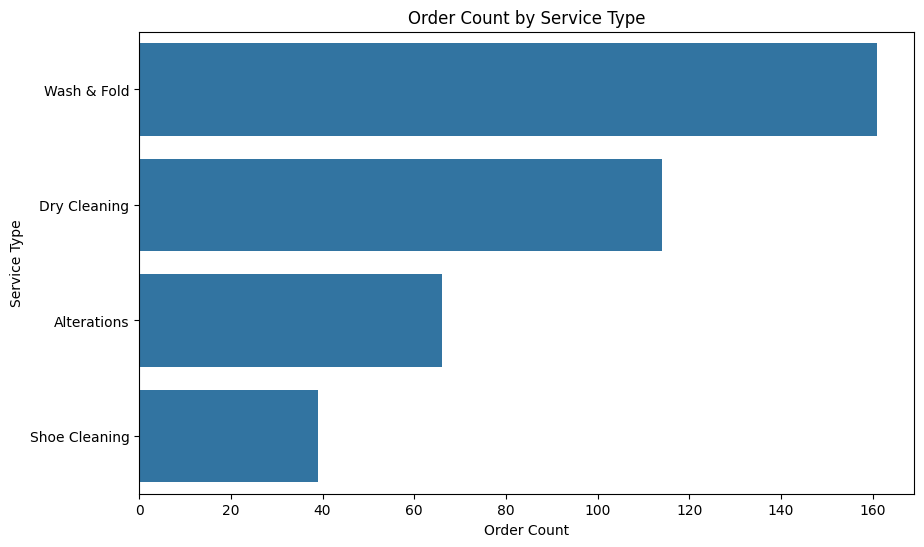

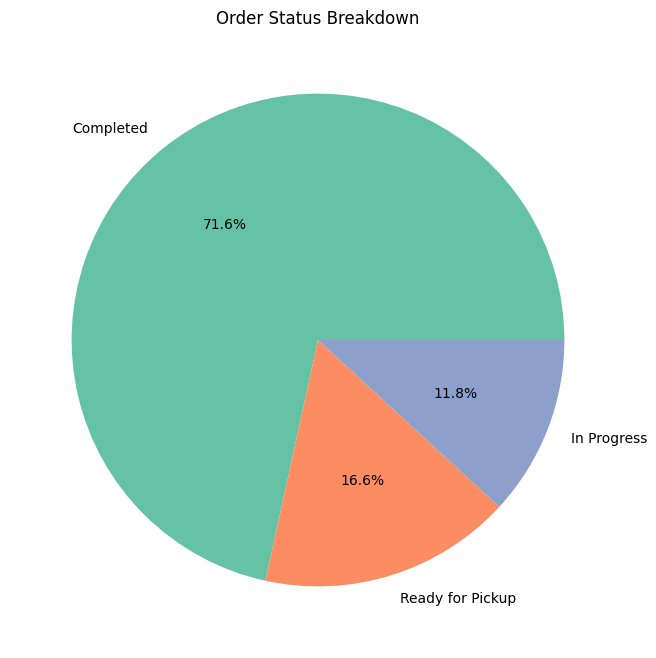

In [41]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: order count by service type (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='order_count', y='service_type', data=order_count_by_service_type, ax=ax)
ax.set_title('Order Count by Service Type')
ax.set_xlabel('Order Count')
ax.set_ylabel('Service Type')
plt.show()

# Chart 2: order status breakdown (pie)
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    breakdown_by_status['status_percentage'],
    labels=breakdown_by_status['status'],
    colors=sns.color_palette('Set2'),
    autopct='%1.1f%%',
)
ax.set_title('Order Status Breakdown')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Wash & Fold has the most orders at **161**. Shoe Cleaning has the fewest at **39**.  
  (주문 1위는 Wash & Fold 161건. Shoe Cleaning은 39건으로 맨 아래)
- Completed orders are **71.58%**. The other two statuses together are **28.42%**.  
  (Completed는 71.58%. 나머지 두 상태를 더하면 28.42%)
- Dry Cleaning has the highest average cost at **$32.34**, while Wash & Fold averages **$17.92**.  
  (평균 비용 1위는 Dry Cleaning $32.34. Wash & Fold 평균은 $17.92)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Staff for Wash & Fold volume. It has **161** orders, **122** more than Shoe Cleaning.  
   (인력은 Wash & Fold 물량에 맞출 것. 161건으로 Shoe Cleaning보다 122건 많음)
2. Keep **28.42%** of orders in view. That is Ready for Pickup **16.58%** plus In Progress **11.84%**.  
   (주문 28.42%를 같이 볼 것. Ready for Pickup 16.58%와 In Progress 11.84%)
3. Do not rank services by order count alone. Dry Cleaning averages **$32.34**, which is **$14.42** above Wash & Fold.  
   (서비스를 주문 건수만으로 순위를 매기지 않기. Dry Cleaning 평균은 $32.34로 Wash & Fold보다 $14.42 높음)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- Chart 2 called `ax.pie` with `x`, `y`, `data`, and `palette`. Matplotlib `pie` takes the sizes as the first argument and the names as `labels`.  
  (차트 2에서 `ax.pie`에 `x`, `y`, `data`, `palette`를 넣었음. Matplotlib `pie`는 첫 인자가 조각 크기이고, 이름은 `labels`)
- The pie also had `set_xlabel('Status')` and `set_ylabel('Percentage')`. The slice labels already show both.  
  (파이 차트에 `set_xlabel('Status')`와 `set_ylabel('Percentage')`도 있었음. 조각 이름에 둘 다 이미 있음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `GROUP BY service_type` with `COUNT(*)` and `ORDER BY order_count DESC` ranks the four services.  
  (`GROUP BY service_type`에 `COUNT(*)`와 `ORDER BY order_count DESC`를 붙이면 네 서비스 순위가 나옴)
- A status share uses the whole table as the denominator: `COUNT(*) / (SELECT COUNT(*) FROM df) * 100`.  
  (상태 비중은 분모를 표 전체로 둠. `COUNT(*) / (SELECT COUNT(*) FROM df) * 100`)
- `ax.pie` needs the percentage column first and `labels` for the status names. `autopct` prints the percent on each slice.  
  (`ax.pie`는 비율 열이 먼저이고, 상태 이름은 `labels`. `autopct`가 조각 위에 퍼센트를 씀)  

---
# 🧠 Reflection

**What was difficult?**  
Making the status percentage use all **380** orders, and calling `pie` with the right arguments.  
(상태 비율의 분모를 주문 380건 전체로 만드는 것, 그리고 `pie`에 맞는 인자를 넣는 것)

**Why?**  
`GROUP BY status` makes a count inside one status. `ax.pie` does not take `data` and `palette` the way `sns.barplot` does.  
(`GROUP BY status`는 한 상태 안의 건수를 만듦. `ax.pie`는 `sns.barplot`처럼 `data`와 `palette`를 받지 않음)

**How did I solve it?**  
Divided each status count by `(SELECT COUNT(*) FROM df)`, then passed `status_percentage` and `labels` into `ax.pie`.  
(각 상태 건수를 `(SELECT COUNT(*) FROM df)`로 나누고, `ax.pie`에는 `status_percentage`와 `labels`를 넣음)

**What would I do differently next time?**  
Check that a pie has no x-axis or y-axis title after the slice labels are on.  
(조각 이름이 붙은 뒤에 파이에 x축·y축 제목이 없는지 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The **161** Wash & Fold orders, the **71.58%** Completed share, and the **$32.34** Dry Cleaning average are clear. `pie` still needs a check that its arguments are sizes and labels.  
(Wash & Fold 161건, Completed 71.58%, Dry Cleaning 평균 $32.34는 이해함. `pie`는 인자가 크기와 이름인지 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The three SQL queries were short. The hard part was the pie chart call.  
(SQL 세 개는 짧았음. 어려운 부분은 파이 차트 호출이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 49 — table merge (Round 4/5)  
  (여러 테이블을 merge로 연결하기)  